## Phase 0: Setup

In [1]:
import os, re, sys, time, warnings, collections
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import state_union, inaugural, stopwords
from nltk.stem import WordNetLemmatizer
from scipy import stats
from scipy.sparse import diags
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import NMF, LatentDirichletAllocation, TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import normalize

for pkg in ["state_union", "inaugural", "punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
os.makedirs("outputs", exist_ok=True)
SEED = 42
np.random.seed(SEED)

def save(name):
    plt.tight_layout()
    plt.savefig(f"outputs/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Historical events used to annotate the charts
EVENTS = {1950: "Korean War", 1965: "Vietnam escalation", 1991: "End of Cold War", 2001: "9/11"}

## Phase 1: Data selection and loading

,Corpus,Speeches,First year,Last year,Presidents,Total words,Median words per speech
0,State of the Union,65,1945,2006,11,347813,4923
1,Inaugural,60,1789,2025,36,141073,2122



Example (first 300 characters of the cleaned 1984 speech):
Mr. Speaker, Mr. President, distinguished Members of the Congress, honored guests, and fellow citizens: Once again, in keeping with time-honored tradition, I have come to report to you on the state of the Union, and I'm pleased to report that America is much improved, and there's good reason to beli


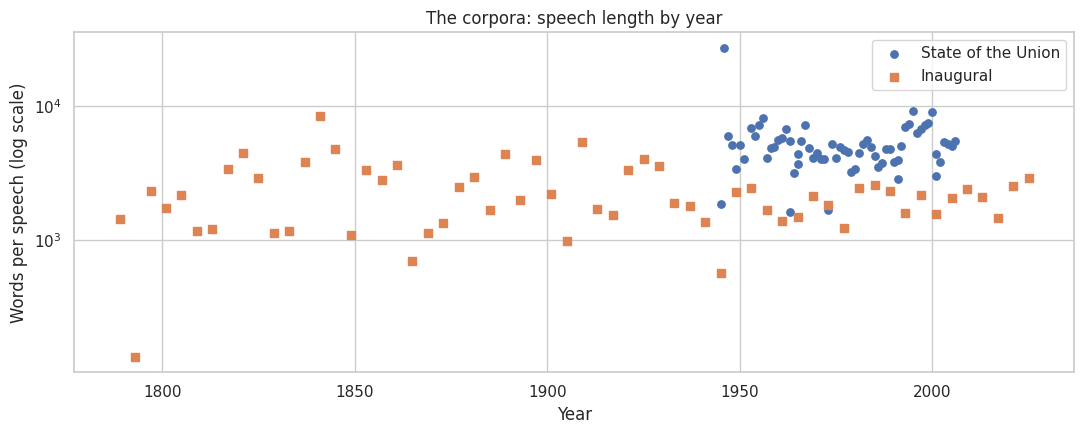

In [21]:
def clean_speech(raw):
    """Remove the title/date header, archive footnotes, speaker labels, bracketed notes and stage directions."""
    raw = raw.replace("\u0104\u015a", "'")                                  # garbled apostrophe in a few files
    for a, b in {"\u2019": "'", "\u2018": "'", "\u201c": '"', "\u201d": '"'}.items():
        raw = raw.replace(a, b)
    lines = raw.splitlines()
    i = 0
    while i < len(lines):
        l = lines[i].strip()
        if l == "" or l.isupper() or re.match(r"^[A-Z][a-z]+\.? \d{1,2}, \d{4}", l):
            i += 1
        else:
            break
    body = lines[i:]
    cut = next((j for j, l in enumerate(body) if re.match(r"^\s*(?:NOTE|Note):", l)), None)
    if cut is not None and cut > 0.8 * len(body):                           # editors' end notes and footnotes
        body = body[:cut]
    body = [l for l in body if not re.match(r"^\s*\?+\s*$", l)]
    text = " ".join(l.strip() for l in body if l.strip())
    text = re.sub(r"\[[^\]]{0,80}\]", " ", text)                         # [1.], [Applause] ...
    text = re.sub(r"\((?:[Aa]pplause|[Ll]aughter)[^)]*\)", " ", text)     # (Applause.)
    text = re.sub(r"\bTHE PRESIDENT:\s*", " ", text)
    text = re.sub(r"[^\x00-\x7F]+", " ", text)                             # any remaining odd characters
    return re.sub(r"\s+", " ", text).strip()

def load_corpus(corpus, name):
    rows = []
    for fid in corpus.fileids():
        m = re.match(r"(\d{4})-(.+?)(?:-\d)?\.txt$", fid)
        rows.append({"fileid": fid, "corpus": name, "year": int(m.group(1)), "president": m.group(2),
                     "text": clean_speech(corpus.raw(fid))})
    df = pd.DataFrame(rows).sort_values(["year", "fileid"]).reset_index(drop=True)
    df["n_words"] = df["text"].str.split().str.len()
    return df

sotu = load_corpus(state_union, "State of the Union")
inaug = load_corpus(inaugural, "Inaugural")

summary = pd.DataFrame({
    "Corpus": [sotu.corpus[0], inaug.corpus[0]],
    "Speeches": [len(sotu), len(inaug)],
    "First year": [sotu.year.min(), inaug.year.min()],
    "Last year": [sotu.year.max(), inaug.year.max()],
    "Presidents": [sotu.president.nunique(), inaug.president.nunique()],
    "Total words": [sotu.n_words.sum(), inaug.n_words.sum()],
    "Median words per speech": [int(sotu.n_words.median()), int(inaug.n_words.median())],
})
display(summary)
summary.to_csv("outputs/table_corpus_summary.csv", index=False)

print("\nExample (first 300 characters of the cleaned 1984 speech):")
print(sotu[sotu.year == 1984].text.iloc[0][:300])

plt.figure(figsize=(11, 4.5))
plt.scatter(sotu.year, sotu.n_words, label="State of the Union", s=28)
plt.scatter(inaug.year, inaug.n_words, label="Inaugural", s=28, marker="s")
plt.yscale("log"); plt.xlabel("Year"); plt.ylabel("Words per speech (log scale)")
plt.title("The corpora: speech length by year"); plt.legend()
save("01_corpus_overview")

## Phase 2: Text preprocessing


In [3]:
PASSAGE_SENTS = 6

def make_passages(df):
    rows = []
    for _, r in df.iterrows():
        sents = [s for s in nltk.sent_tokenize(r["text"]) if len(s.split()) >= 3]
        chunks = [sents[i:i + PASSAGE_SENTS] for i in range(0, len(sents), PASSAGE_SENTS)]
        if len(chunks) > 1 and len(chunks[-1]) < 3:
            chunks[-2] += chunks.pop()
        for c in chunks:
            rows.append({"fileid": r["fileid"], "year": r["year"], "president": r["president"], "text": " ".join(c)})
    return pd.DataFrame(rows)

passages = make_passages(sotu)
print(f"{len(sotu)} speeches -> {len(passages):,} passages of about {passages.text.str.split().str.len().mean():.0f} words")

65 speeches -> 2,866 passages of about 122 words


In [4]:
lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=None)
def lemma(w):
    return lemmatizer.lemmatize(w)

CUSTOM_STOP = {"applause", "mr", "mrs", "upon", "shall", "let", "also", "would", "could", "may", "must", "might", "say",
               "said", "get", "go", "come", "make", "made", "one", "two", "every", "much", "many", "even", "still",
               "well", "just", "like", "year", "new", "must", "need", "want", "know", "think", "take", "give"}
STOP = set(stopwords.words("english")) | CUSTOM_STOP

def raw_tokens(text):
    """All alphabetic tokens in lower case (used for style measures)."""
    return re.findall(r"[a-z]+", text.lower().replace("\u2019", "'").replace("'s", ""))

def content_tokens(text):
    """Lemmatised content words: no stopwords, at least 3 letters."""
    out = []
    for w in raw_tokens(text):
        if len(w) >= 3 and w not in STOP:
            l = lemma(w)
            if l not in STOP:
                out.append(l)
    return out

example = passages.text.iloc[300]
print("ORIGINAL:\n", example, "\n")
print("TOKENS  :\n", raw_tokens(example)[:25], "...\n")
print("LEMMATISED CONTENT WORDS:\n", content_tokens(example))

ORIGINAL:
 We must also go on to support the International Trade Organization, through which we hope to obtain worldwide agreement on a code of fair conduct in international trade. Our present major effort toward economic reconstruction is to support the program for recovery developed by the countries of Europe. In my recent message to the Congress, I outlined the reasons why it is wise and necessary for the United States to extend this support. I want to reaffirm my belief in the soundness and the promise of this proposal. When the European economy is strengthened, the product of its industry will be of benefit to many other areas of economic distress. The ability of free men to overcome hunger and despair will be a moral stimulus to the entire world. 

TOKENS  :
 ['we', 'must', 'also', 'go', 'on', 'to', 'support', 'the', 'international', 'trade', 'organization', 'through', 'which', 'we', 'hope', 'to', 'obtain', 'worldwide', 'agreement', 'on', 'a', 'code', 'of', 'fair', 'conduct'] ...

State of the Union: 163,216 content tokens | 10,435 distinct lemmas


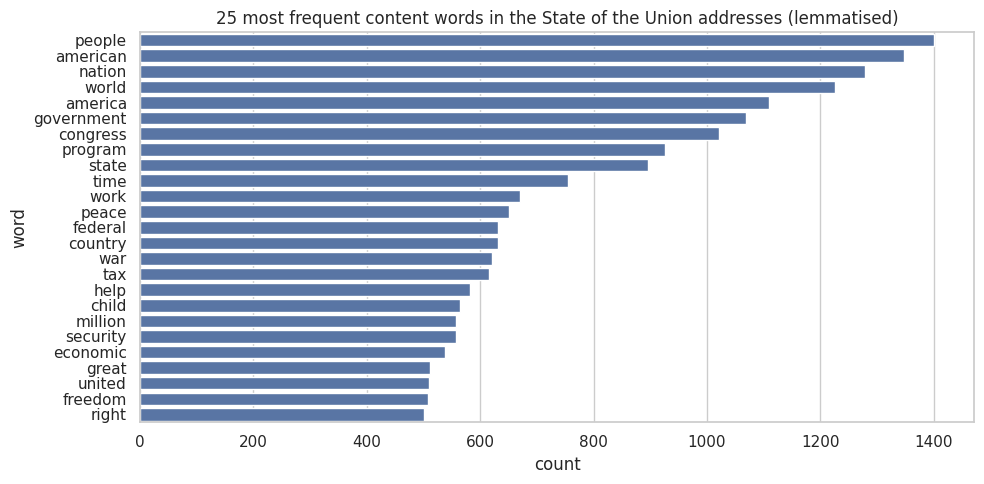

In [5]:
passages["proc"] = passages["text"].map(lambda t: " ".join(content_tokens(t)))
sotu["content"] = sotu["text"].map(content_tokens)
sotu["n_content"] = sotu["content"].map(len)
inaug["content"] = inaug["text"].map(content_tokens)

all_counts = collections.Counter(w for toks in sotu["content"] for w in toks)
print(f"State of the Union: {sum(all_counts.values()):,} content tokens | {len(all_counts):,} distinct lemmas")

top = pd.DataFrame(all_counts.most_common(25), columns=["word", "count"])
sns.barplot(data=top, y="word", x="count", color="#4c72b0")
plt.title("25 most frequent content words in the State of the Union addresses (lemmatised)")
save("02_top_words")
top.to_csv("outputs/table_top_words.csv", index=False)

## Phase 3: Frequency analysis and trend detection


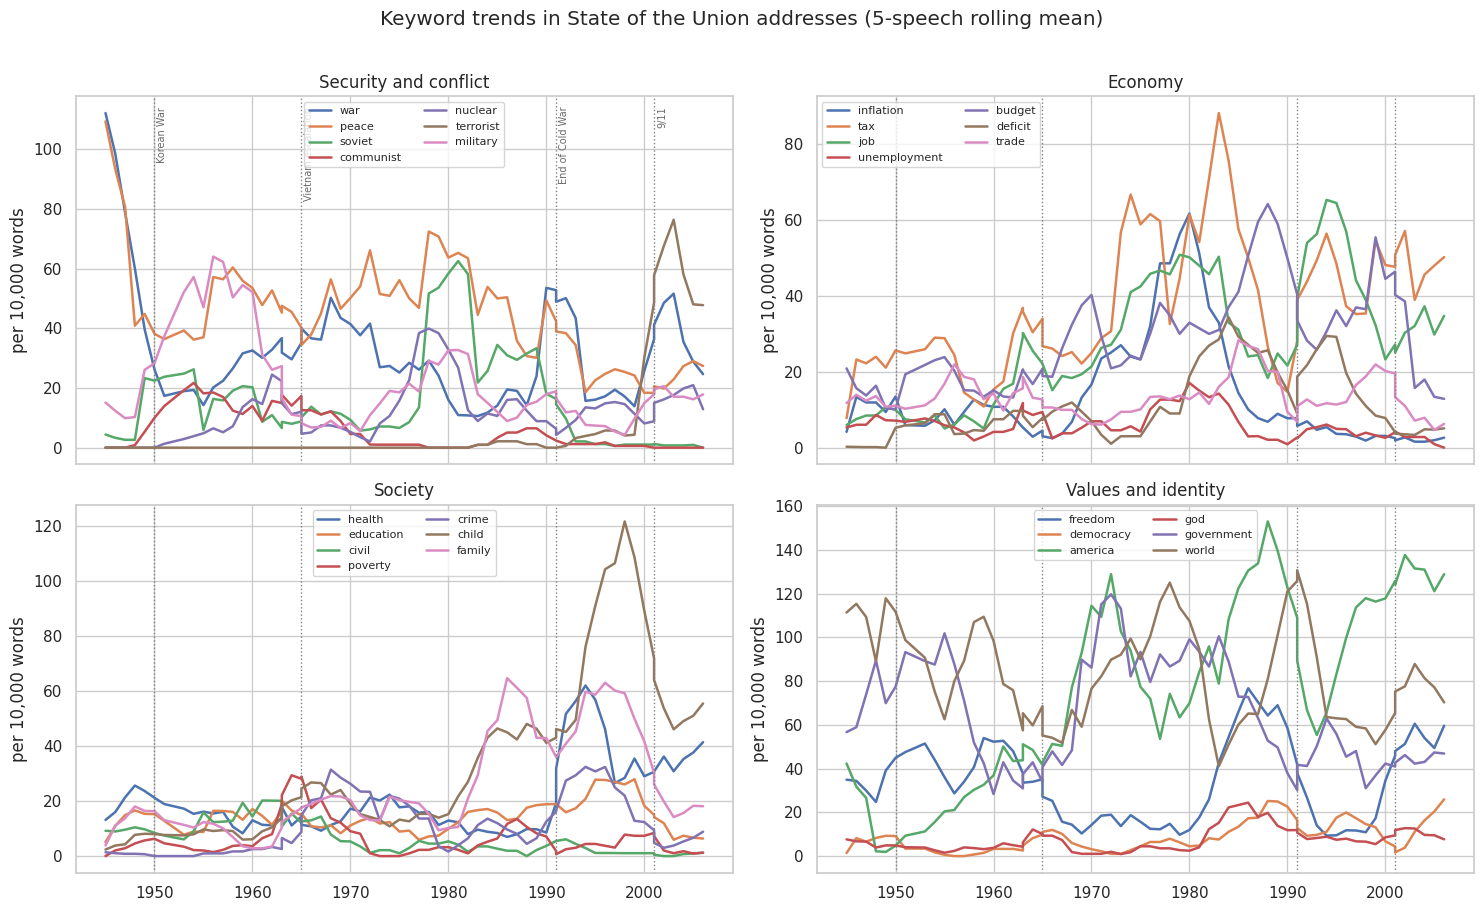

In [6]:
KEYWORDS = {
    "Security and conflict": ["war", "peace", "soviet", "communist", "nuclear", "terrorist", "military"],
    "Economy": ["inflation", "tax", "job", "unemployment", "budget", "deficit", "trade"],
    "Society": ["health", "education", "civil", "poverty", "crime", "child", "family"],
    "Values and identity": ["freedom", "democracy", "america", "god", "government", "world"],
}
all_kw = sorted({w for ws in KEYWORDS.values() for w in ws})

def identity(x):
    return x

kw_vec = CountVectorizer(vocabulary=all_kw, tokenizer=identity, preprocessor=identity, token_pattern=None, lowercase=False)
kw_counts = kw_vec.fit_transform(sotu["content"]).toarray()
kw_rates = pd.DataFrame(kw_counts / sotu["n_content"].values[:, None] * 10000, columns=all_kw)
kw_rates["year"] = sotu["year"].values
smooth = kw_rates.sort_values("year").set_index("year").rolling(5, center=True, min_periods=1).mean()

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for ax, (title, words) in zip(axes.ravel(), KEYWORDS.items()):
    for w in words:
        ax.plot(smooth.index, smooth[w], label=w, lw=1.8)
    for yr in EVENTS:
        ax.axvline(yr, color="grey", ls=":", lw=1)
    ax.set_title(title); ax.set_ylabel("per 10,000 words"); ax.legend(fontsize=8, ncol=2)
for yr, name in EVENTS.items():
    axes[0, 0].text(yr + 0.3, axes[0, 0].get_ylim()[1] * 0.97, name, rotation=90, va="top", fontsize=7, color="dimgrey")
plt.suptitle("Keyword trends in State of the Union addresses (5-speech rolling mean)", y=1.01)
save("03_keyword_trends")

192 words tested (in at least 15 speeches, 150+ occurrences)
90 of 192 words show a significant monotonic trend (FDR q < 0.05); 41 rising, 49 falling


,word (rising),rho (rising),q (rising),word (falling),rho (falling),q (falling)
0,child,0.787,0.000,present,-0.677,0.0
1,reform,0.701,0.000,labor,-0.661,0.0
2,america,0.692,0.000,expenditure,-0.593,0.0
3,tonight,0.683,0.000,full,-0.582,0.0
4,american,0.621,0.000,development,-0.576,0.0
5,day,0.565,0.000,farm,-0.562,0.0
6,work,0.549,0.000,increased,-0.554,0.0
7,woman,0.536,0.000,resource,-0.540,0.0
8,job,0.534,0.000,fiscal,-0.539,0.0
9,ask,0.513,0.000,purpose,-0.535,0.0


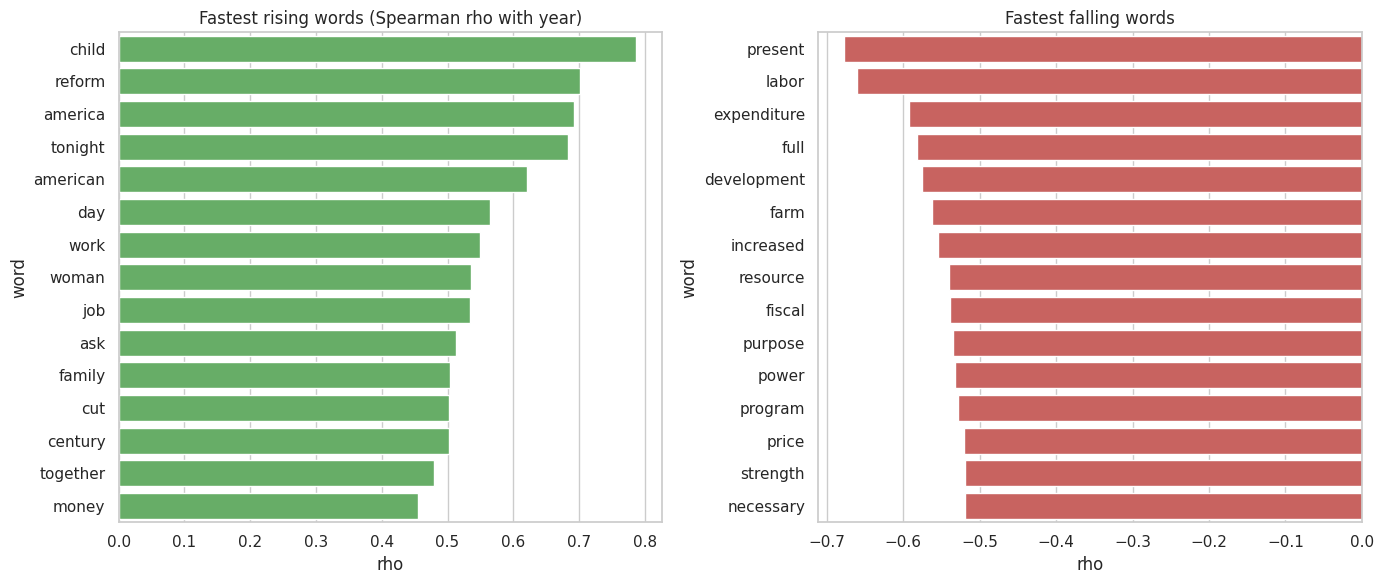

In [7]:
# ---- Trend detection over the whole vocabulary: Spearman correlation of each word's rate with the year ----
vec = CountVectorizer(tokenizer=identity, preprocessor=identity, token_pattern=None, lowercase=False, min_df=15)
S = vec.fit_transform(sotu["content"])
vocab = vec.get_feature_names_out()
keep = np.asarray(S.sum(axis=0)).ravel() >= 150
S, vocab = S[:, keep], vocab[keep]
rates = pd.DataFrame(S.toarray() / sotu["n_content"].values[:, None] * 10000, columns=vocab)
print(f"{len(vocab):,} words tested (in at least 15 speeches, 150+ occurrences)")

rho, pval = np.zeros(len(vocab)), np.zeros(len(vocab))
for j, w in enumerate(vocab):
    rho[j], pval[j] = stats.spearmanr(sotu["year"], rates[w])

def bh_fdr(p):
    """Benjamini-Hochberg false discovery rate (q-values)."""
    p = np.asarray(p); n = len(p); order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    q = np.empty(n); q[order] = np.clip(ranked, 0, 1)
    return q

trend = pd.DataFrame({"word": vocab, "rho": rho, "p": pval, "q": bh_fdr(pval)})
half = sotu["year"].median()
trend["rate_first_half"] = rates[sotu["year"] <= half].mean().values
trend["rate_second_half"] = rates[sotu["year"] > half].mean().values
sig = trend[trend.q < 0.05]
print(f"{len(sig)} of {len(trend)} words show a significant monotonic trend (FDR q < 0.05); "
      f"{(sig.rho > 0).sum()} rising, {(sig.rho < 0).sum()} falling")

rising = sig.sort_values("rho", ascending=False).head(15)
falling = sig.sort_values("rho").head(15)
display(pd.concat([rising.reset_index(drop=True).add_suffix(" (rising)")[["word (rising)", "rho (rising)", "q (rising)"]],
                   falling.reset_index(drop=True).add_suffix(" (falling)")[["word (falling)", "rho (falling)", "q (falling)"]]], axis=1).round(3))
pd.concat([rising.assign(direction="rising"), falling.assign(direction="falling")]).to_csv("outputs/table_rising_falling_words.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=rising, y="word", x="rho", color="#5cb85c", ax=axes[0]); axes[0].set_title("Fastest rising words (Spearman rho with year)")
sns.barplot(data=falling, y="word", x="rho", color="#d9534f", ax=axes[1]); axes[1].set_title("Fastest falling words")
save("04_rising_falling_words")

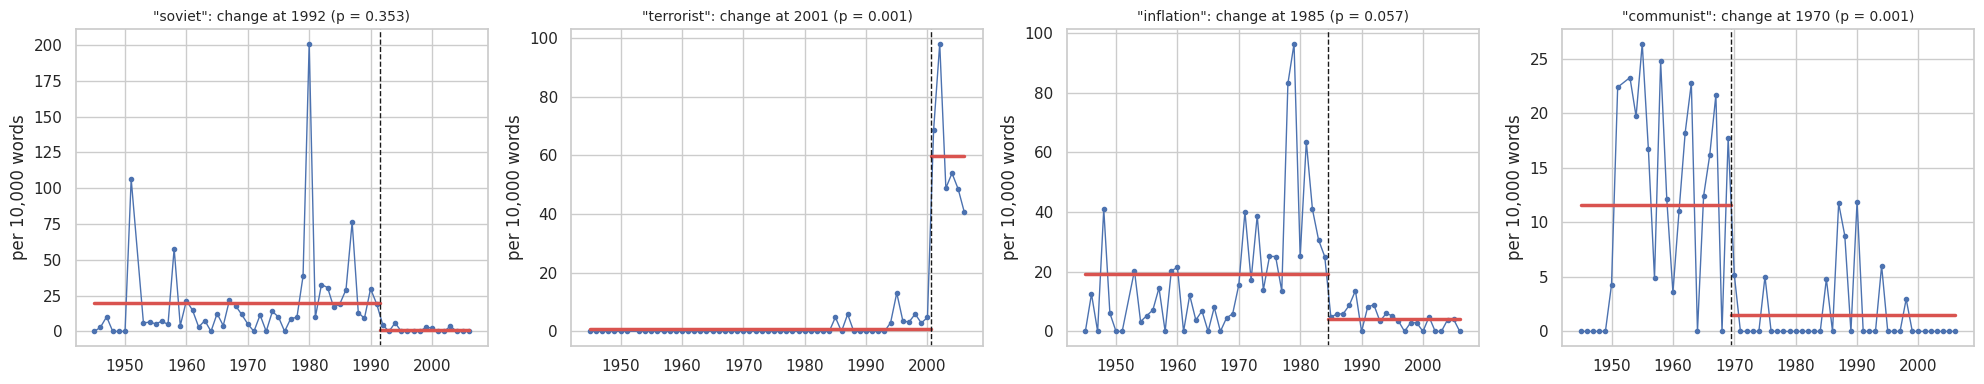

,word,change_year,mean_before,mean_after,explained,p
0,soviet,1992,19.800,1.300,0.069,0.353
1,terrorist,2001,0.857,59.791,0.884,0.001
2,inflation,1985,19.166,4.222,0.141,0.057
3,communist,1970,11.594,1.526,0.365,0.001


In [8]:
# ---- Change-point detection: where does a word's usage jump? (two-segment mean model + permutation test) ----
def best_change_point(y, min_seg=5):
    best_i, best_sse = None, np.inf
    for i in range(min_seg, len(y) - min_seg + 1):
        sse = ((y[:i] - y[:i].mean()) ** 2).sum() + ((y[i:] - y[i:].mean()) ** 2).sum()
        if sse < best_sse:
            best_i, best_sse = i, sse
    return best_i, best_sse

def change_point_test(years, y, n_perm=1000, seed=SEED):
    y = np.asarray(y, dtype=float)
    i, sse = best_change_point(y)
    total = ((y - y.mean()) ** 2).sum()
    stat = 1 - sse / total                                     # share of variance explained by one step change
    rng = np.random.default_rng(seed)
    perm = [1 - best_change_point(rng.permutation(y))[1] / total for _ in range(n_perm)]
    p = (1 + sum(s >= stat for s in perm)) / (n_perm + 1)
    return {"change_year": int(years[i]), "mean_before": y[:i].mean(), "mean_after": y[i:].mean(), "explained": stat, "p": p}

annual = kw_rates.groupby("year").mean()
CP_WORDS = ["soviet", "terrorist", "inflation", "communist"]
cp_rows, fig_axes = [], plt.subplots(1, len(CP_WORDS), figsize=(5 * len(CP_WORDS), 4))[1]
for ax, w in zip(np.atleast_1d(fig_axes), CP_WORDS):
    res = change_point_test(annual.index.values, annual[w].values)
    cp_rows.append({"word": w, **res})
    ax.plot(annual.index, annual[w], "o-", ms=3, lw=1, color="#4c72b0")
    ax.plot([annual.index.min(), res["change_year"] - 0.5], [res["mean_before"]] * 2, color="#d9534f", lw=2.5)
    ax.plot([res["change_year"] - 0.5, annual.index.max()], [res["mean_after"]] * 2, color="#d9534f", lw=2.5)
    ax.axvline(res["change_year"] - 0.5, color="k", ls="--", lw=1)
    ax.set_title(f'"{w}": change at {res["change_year"]} (p = {res["p"]:.3f})', fontsize=10)
    ax.set_ylabel("per 10,000 words")
save("05_change_points")
change_points = pd.DataFrame(cp_rows)
display(change_points.round(3))
change_points.to_csv("outputs/table_change_points.csv", index=False)

In [9]:
# ---- Distinctive vocabulary of each decade (log-odds with an informative prior, "Fightin' Words" method) ----
dec_vec = CountVectorizer(vocabulary=list(vocab), tokenizer=identity, preprocessor=identity, token_pattern=None, lowercase=False)
D = dec_vec.fit_transform(sotu["content"]).toarray()
decade = (sotu["year"] // 10 * 10).values
decades = sorted(set(decade))
alpha0 = 500.0
prior = D.sum(0) / D.sum() * alpha0

rows = {}
for d in decades:
    yi, yj = D[decade == d].sum(0), D[decade != d].sum(0)
    ni, nj = yi.sum(), yj.sum()
    delta = (np.log((yi + prior) / (ni + alpha0 - yi - prior)) - np.log((yj + prior) / (nj + alpha0 - yj - prior)))
    z = delta / np.sqrt(1 / (yi + prior) + 1 / (yj + prior))
    rows[f"{d}s"] = [vocab[k] for k in np.argsort(-z)[:8]]
decade_words = pd.DataFrame(rows, index=[f"#{i}" for i in range(1, 9)])
display(decade_words)
decade_words.to_csv("outputs/table_distinctive_words_by_decade.csv")

,1940s,1950s,1960s,1970s,1980s,1990s,2000s
#1,dollar,military,nation,energy,soviet,child,america
#2,war,strength,seek,inflation,spending,work,child
#3,fiscal,free,men,goal,america,care,ask
#4,expenditure,economic,city,federal,deficit,community,weapon
#5,million,defense,effort,union,rate,cut,woman
#6,price,development,cannot,foreign,growth,century,yet
#7,production,purpose,hope,congress,future,challenge,tonight
#8,housing,administration,progress,government,reduction,thing,care


## Phase 4: Topic modelling


Document-term matrix: 2,866 passages x 2,784 words
k =  4 fitted in 28s
k =  6 fitted in 29s
k =  8 fitted in 29s
k = 10 fitted in 31s
k = 12 fitted in 29s
k = 15 fitted in 29s
k = 20 fitted in 34s


Algorithm,LDA,NMF
k,,
4,0.1091,0.1622
6,0.1121,0.1804
8,0.1144,0.2125
10,0.1164,0.2323
12,0.1224,0.2164
15,0.1377,0.2224
20,0.1326,0.2223


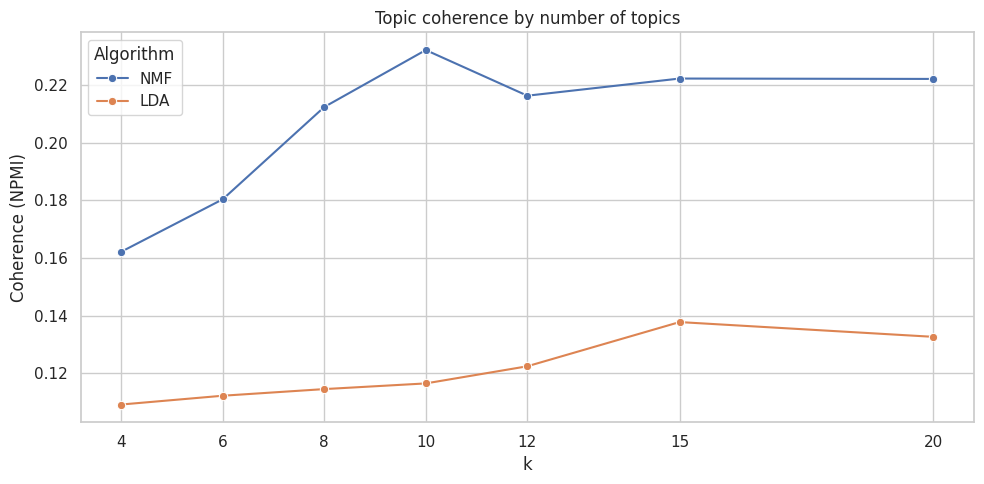


Best coherence: NMF with k = 10 (NPMI = 0.2323)


In [10]:
cv = CountVectorizer(max_df=0.4, min_df=8, token_pattern=r"(?u)\b[a-z]{3,}\b")
X_counts = cv.fit_transform(passages["proc"])
tfidf = TfidfVectorizer(max_df=0.4, min_df=8, token_pattern=r"(?u)\b[a-z]{3,}\b", sublinear_tf=True)
X_tfidf = tfidf.fit_transform(passages["proc"])
t_vocab = cv.get_feature_names_out()
assert list(t_vocab) == list(tfidf.get_feature_names_out())
print(f"Document-term matrix: {X_counts.shape[0]:,} passages x {X_counts.shape[1]:,} words")

B = (X_counts > 0).astype(np.float64).tocsc()                   # binary presence, for coherence

def top_indices(components, n=10):
    return [np.argsort(-row)[:n] for row in components]

def npmi_coherence(components, n=10):
    D_ = B.shape[0]; df = np.asarray(B.sum(axis=0)).ravel(); scores = []
    for idx in top_indices(components, n):
        sub = B[:, idx]
        co = (sub.T @ sub).toarray()
        vals = []
        for a in range(len(idx)):
            for b in range(a + 1, len(idx)):
                p_ab = co[a, b] / D_
                vals.append(-1.0 if p_ab == 0 else np.log(p_ab / ((df[idx[a]] / D_) * (df[idx[b]] / D_))) / (-np.log(p_ab)))
        scores.append(np.mean(vals))
    return float(np.mean(scores))

K_VALUES = [4, 6, 8, 10, 12, 15, 20]
models, coh_rows = {}, []
for k in K_VALUES:
    t0 = time.time()
    nmf = NMF(n_components=k, init="nndsvd", random_state=SEED, max_iter=400).fit(X_tfidf)
    lda = LatentDirichletAllocation(n_components=k, learning_method="batch", max_iter=25, random_state=SEED).fit(X_counts)
    models[("NMF", k)], models[("LDA", k)] = nmf, lda
    coh_rows += [{"Algorithm": "NMF", "k": k, "Coherence (NPMI)": npmi_coherence(nmf.components_)},
                 {"Algorithm": "LDA", "k": k, "Coherence (NPMI)": npmi_coherence(lda.components_)}]
    print(f"k = {k:2d} fitted in {time.time() - t0:.0f}s")

coh = pd.DataFrame(coh_rows)
display(coh.pivot(index="k", columns="Algorithm", values="Coherence (NPMI)").round(4))
coh.to_csv("outputs/table_topic_coherence.csv", index=False)

sns.lineplot(data=coh, x="k", y="Coherence (NPMI)", hue="Algorithm", marker="o")
plt.title("Topic coherence by number of topics"); plt.xticks(K_VALUES)
save("06_topic_coherence")

best = coh.sort_values("Coherence (NPMI)", ascending=False).iloc[0]
FINAL_ALGO, FINAL_K = best["Algorithm"], int(best["k"])
print(f"\nBest coherence: {FINAL_ALGO} with k = {FINAL_K} (NPMI = {best['Coherence (NPMI)']:.4f})")
# To use a different number of topics, set for example: FINAL_ALGO, FINAL_K = "NMF", 10

In [11]:
final = models[(FINAL_ALGO, FINAL_K)]
W = final.transform(X_tfidf if FINAL_ALGO == "NMF" else X_counts)
W = W / np.maximum(W.sum(axis=1, keepdims=True), 1e-12)         # each passage: proportions of topics
passages["topic"] = W.argmax(axis=1)

topic_words = {t: [t_vocab[i] for i in np.argsort(-final.components_[t])[:12]] for t in range(FINAL_K)}
topic_labels = {t: f"T{t + 1}: " + ", ".join(topic_words[t][:3]) for t in range(FINAL_K)}

# prevalence: mean over passages of each speech, then over speeches (every speech equal weight)
topic_cols = [topic_labels[t] for t in range(FINAL_K)]
topic_df = pd.DataFrame(W, columns=topic_cols)
topic_df["fileid"], topic_df["year"] = passages["fileid"].values, passages["year"].values
by_speech = topic_df.groupby(["fileid", "year"]).mean().reset_index()
by_year = by_speech.drop(columns="fileid").groupby("year").mean()

topics_table = pd.DataFrame({"Topic": topic_cols, "Top words": [", ".join(topic_words[t]) for t in range(FINAL_K)],
                             "Overall share (%)": (by_speech[topic_cols].mean().values * 100).round(1),
                             "Peak decade": [f"{int(by_year[c].groupby(by_year.index // 10 * 10).mean().idxmax())}s" for c in topic_cols]})
pd.set_option("display.max_colwidth", 120)
display(topics_table)
topics_table.to_csv("outputs/table_topics.csv", index=False)

print("\nMost representative passage of each topic:")
for t in range(FINAL_K):
    i = int(np.argmax(W[:, t]))
    print(f"\n{topic_labels[t]}  [{passages.year[i]}, {passages.president[i]}]\n   {passages.text[i][:260]}...")

,Topic,Top words,Overall share (%),Peak decade
0,"T1: world, peace, nation","world, peace, nation, united, free, freedom, economic, state, international, trade, policy, people",13.0,1950s
1,"T2: federal, government, program","federal, government, program, local, state, congress, legislation, resource, public, law, development, citizen",11.7,1950s
2,"T3: child, school, parent","child, school, parent, help, teacher, education, family, community, student, college, work, support",8.5,1990s
3,"T4: tax, cut, budget","tax, cut, budget, spending, rate, deficit, percent, growth, reduction, income, federal, inflation",8.6,1980s
4,"T5: president, congress, member","president, congress, member, speaker, union, state, tonight, house, ago, report, time, fellow",10.2,1970s
5,"T6: defense, force, military","defense, force, military, nuclear, weapon, soviet, security, arm, missile, strategic, threat, armed",9.9,2000s
6,"T7: dollar, fiscal, expenditure","dollar, fiscal, expenditure, billion, million, war, estimated, total, budget, appropriation, estimate, program",4.6,1940s
7,"T8: health, care, insurance","health, care, insurance, medical, coverage, security, social, system, benefit, medicare, cost, american",6.2,1990s
8,"T9: price, wage, farm","price, wage, farm, production, labor, economy, farmer, business, worker, market, inflation, employment",9.0,1940s
9,"T10: america, american, god","america, american, god, people, together, bless, life, great, day, century, freedom, hope",18.4,2000s



Most representative passage of each topic:

T1: world, peace, nation  [1955, Eisenhower]
   In the past year, there has been progress justifying hope, both for continuing peace and for the ultimate rule of freedom and justice in the world. Free nations are collectively stronger than at any time in recent years. Just as nations of this Hemisphere, in ...

T2: federal, government, program  [1957, Eisenhower]
   Our soil, water, mineral, forest, fish, and wildlife resources are being conserved and improved more effectively. Their conservation and development are vital to the present and future strength of the Nation. But they must not be the concern of the Federal Gov...

T3: child, school, parent  [1996, Clinton]
   I challenge all our schools to teach character education, to teach good values and good citizenship. And if it means that teenagers will stop killing each other over designer jackets, then our public schools should be able to require their students to wear sch...

T4: tax, c

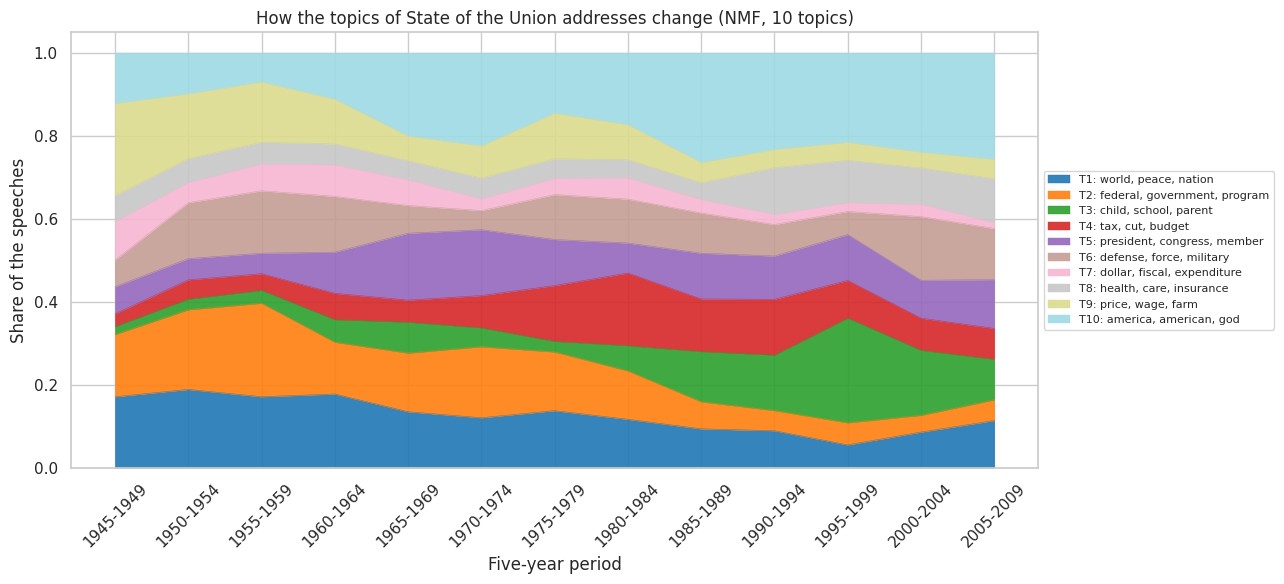

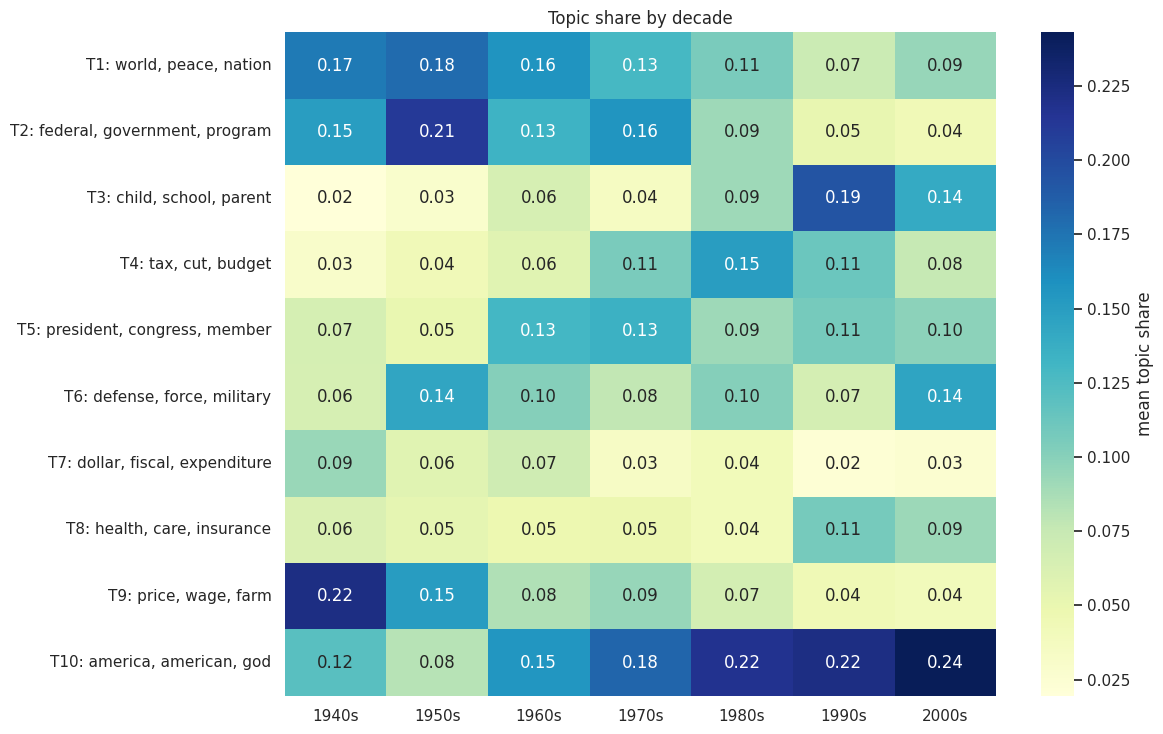

,Topic,rho,p,q
2,"T3: child, school, parent",0.7568,0.0000,0.0000
9,"T10: america, american, god",0.5790,0.0000,0.0000
3,"T4: tax, cut, budget",0.4989,0.0000,0.0000
4,"T5: president, congress, member",0.3271,0.0078,0.0098
7,"T8: health, care, insurance",0.3155,0.0105,0.0116
5,"T6: defense, force, military",0.0075,0.9525,0.9525
6,"T7: dollar, fiscal, expenditure",-0.5117,0.0000,0.0000
0,"T1: world, peace, nation",-0.5479,0.0000,0.0000
8,"T9: price, wage, farm",-0.6467,0.0000,0.0000
1,"T2: federal, government, program",-0.6928,0.0000,0.0000


In [12]:
# ---- Topic prevalence over time ----
bins = (by_year.index // 5 * 5)
area = by_year.groupby(bins).mean()
area = area.div(area.sum(axis=1), axis=0)
area.index = [f"{b}-{b + 4}" for b in area.index]
area.plot(kind="area", stacked=True, figsize=(13, 6), colormap="tab20", alpha=0.9, linewidth=0.3)
plt.xticks(range(len(area)), area.index, rotation=45); plt.ylabel("Share of the speeches"); plt.xlabel("Five-year period")
plt.title(f"How the topics of State of the Union addresses change ({FINAL_ALGO}, {FINAL_K} topics)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
save("07_topic_prevalence_area")

dec = by_year.groupby(by_year.index // 10 * 10).mean()
dec.index = [f"{d}s" for d in dec.index]
plt.figure(figsize=(12, 0.55 * FINAL_K + 2))
sns.heatmap(dec.T, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "mean topic share"})
plt.title("Topic share by decade"); plt.ylabel("")
save("08_topic_decade_heatmap")

trend_rows = []
for c in topic_cols:
    r, p = stats.spearmanr(by_speech["year"], by_speech[c])
    trend_rows.append({"Topic": c, "rho": r, "p": p})
topic_trends = pd.DataFrame(trend_rows).sort_values("rho", ascending=False)
topic_trends["q"] = bh_fdr(topic_trends["p"].values)
display(topic_trends.round(4))
topic_trends.to_csv("outputs/table_topic_trends.csv", index=False)

## Phase 5: Clustering


In [13]:
svd = TruncatedSVD(n_components=100, random_state=SEED)
Z = normalize(svd.fit_transform(X_tfidf))
print(f"SVD with 100 components keeps {svd.explained_variance_ratio_.sum():.1%} of the variance")

sil_rows = []
for k in range(4, 15):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    sil_rows.append({"k": k, "silhouette": silhouette_score(Z, km.labels_, sample_size=2000, random_state=SEED)})
sil = pd.DataFrame(sil_rows)
display(sil.round(4))
BEST_KC = int(sil.sort_values("silhouette", ascending=False).iloc[0]["k"])
print("Best silhouette at k =", BEST_KC)
# To choose another number of clusters, set for example: BEST_KC = 8

km = KMeans(n_clusters=BEST_KC, n_init=10, random_state=SEED).fit(Z)
passages["cluster"] = km.labels_
cluster_terms = {}
for c in range(BEST_KC):
    centroid = np.asarray(X_tfidf[km.labels_ == c].mean(axis=0)).ravel()
    cluster_terms[c] = [t_vocab[i] for i in np.argsort(-centroid)[:10]]
cl_table = pd.DataFrame({"Cluster": [f"C{c + 1}" for c in range(BEST_KC)],
                         "Passages": np.bincount(km.labels_, minlength=BEST_KC),
                         "Top terms": [", ".join(cluster_terms[c]) for c in range(BEST_KC)],
                         "Median year": [int(passages.year[passages.cluster == c].median()) for c in range(BEST_KC)]})
display(cl_table)
cl_table.to_csv("outputs/table_clusters.csv", index=False)
print("\nAgreement between the topic model (dominant topic) and K-means clusters: adjusted Rand index =",
      round(adjusted_rand_score(passages["topic"], passages["cluster"]), 3))

SVD with 100 components keeps 22.9% of the variance


,k,silhouette
0,4,0.0312
1,5,0.0319
2,6,0.0320
3,7,0.0309
4,8,0.0349
5,9,0.0348
6,10,0.0374
7,11,0.0384
8,12,0.0390
9,13,0.0394


Best silhouette at k = 14


,Cluster,Passages,Top terms,Median year
0,C1,88,"dollar, expenditure, fiscal, billion, million, estimated, war, total, budget, appropriation",1946
1,C2,138,"president, congress, member, speaker, union, state, house, american, great, tonight",1974
2,C3,195,"price, labor, farm, production, wage, farmer, economy, inflation, management, agriculture",1950
3,C4,151,"budget, spending, deficit, federal, cut, billion, government, tax, growth, program",1986
4,C5,112,"school, child, teacher, student, education, college, parent, help, classroom, high",1996
5,C6,133,"health, care, social, insurance, security, system, coverage, medical, benefit, american",1994
6,C7,157,"tax, rate, income, percent, job, business, inflation, reduction, economy, cut",1981
7,C8,343,"federal, program, government, congress, state, legislation, resource, local, energy, public",1961
8,C9,441,"world, peace, nation, united, free, freedom, trade, america, soviet, people",1966
9,C10,100,"terrorist, iraq, weapon, saddam, terror, regime, nuclear, iraqi, hussein, world",2003



Agreement between the topic model (dominant topic) and K-means clusters: adjusted Rand index = 0.556


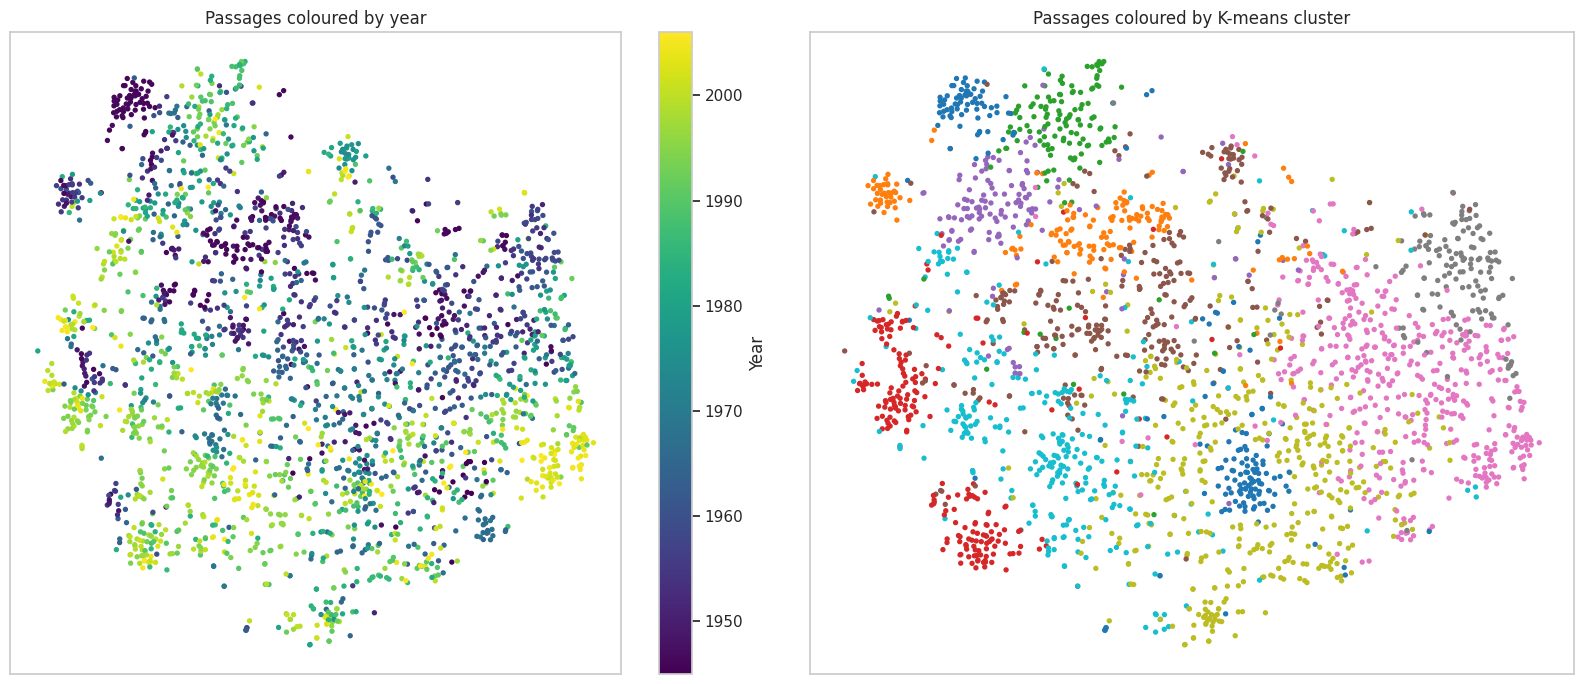

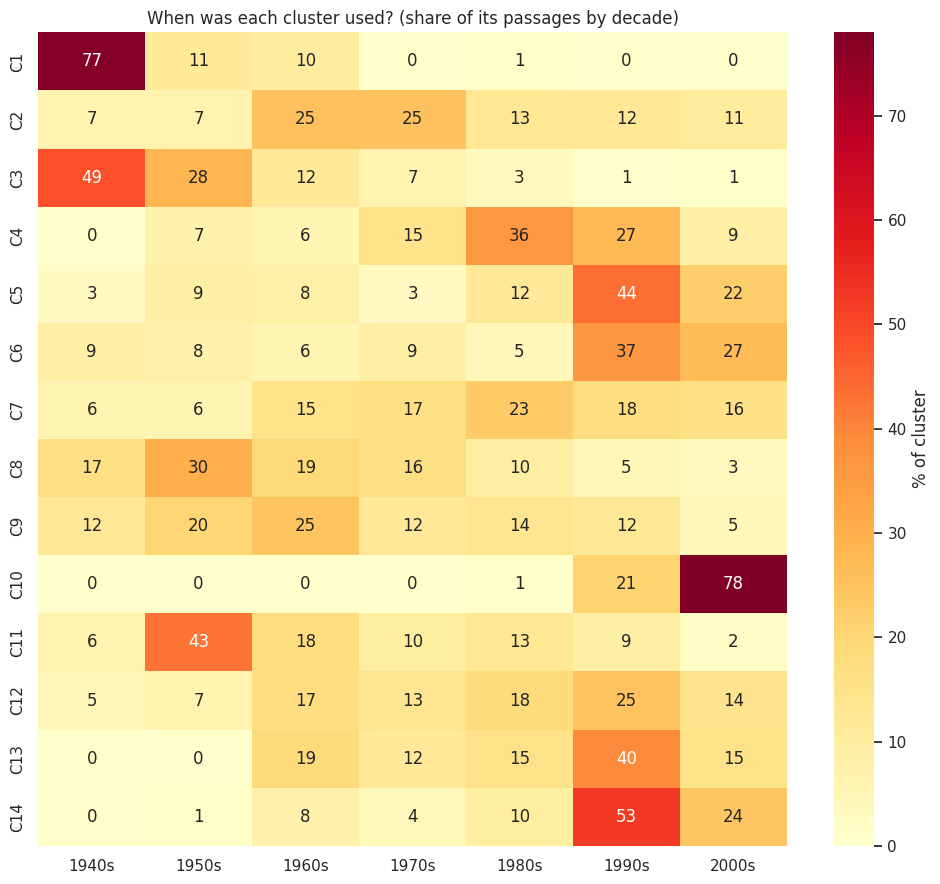

In [14]:
# ---- 2D map of the passages (t-SNE), coloured by decade and by cluster ----
rng = np.random.default_rng(SEED)
idx = rng.choice(len(passages), size=min(2500, len(passages)), replace=False)
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z[idx])
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sc = axes[0].scatter(emb[:, 0], emb[:, 1], c=passages.year.values[idx], cmap="viridis", s=8)
plt.colorbar(sc, ax=axes[0], label="Year"); axes[0].set_title("Passages coloured by year")
sc2 = axes[1].scatter(emb[:, 0], emb[:, 1], c=passages.cluster.values[idx], cmap="tab10", s=8)
axes[1].set_title("Passages coloured by K-means cluster")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
save("09_cluster_map")

comp = pd.crosstab(passages["cluster"], passages["year"] // 10 * 10, normalize="index") * 100
comp.index = [f"C{c + 1}" for c in comp.index]; comp.columns = [f"{c}s" for c in comp.columns]
plt.figure(figsize=(10, 0.5 * BEST_KC + 2))
sns.heatmap(comp, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% of cluster"})
plt.title("When was each cluster used? (share of its passages by decade)")
save("10_cluster_decade_heatmap")

,eras,silhouette
0,3,0.1501
1,4,0.1777
2,5,0.2110
3,6,0.2228
4,7,0.2483
5,8,0.2583


,Era,start,end,speeches,presidents
0,E1,1945,1969,26,"Truman, Eisenhower, Kennedy, Johnson"
1,E2,1970,1974,5,Nixon
2,E3,1975,1992,19,"Ford, Carter, Reagan, Bush"
3,E4,1993,2000,8,Clinton
4,E5,2001,2006,7,GWBush


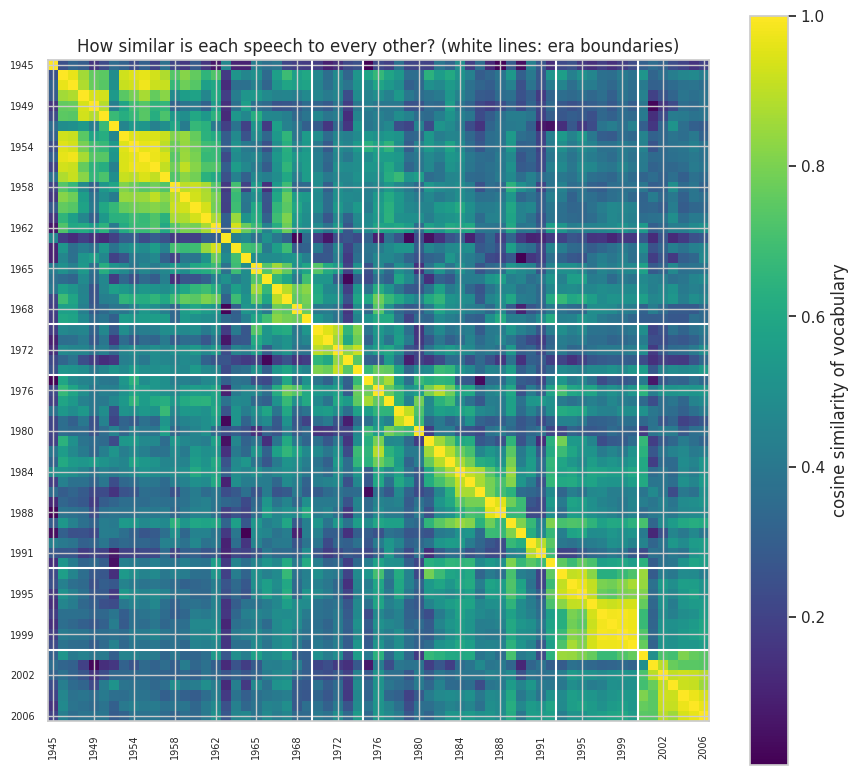

In [15]:
# ---- Language eras: constrained hierarchical clustering of whole speeches ----
sotu["proc"] = sotu["content"].map(" ".join)
sp_vec = TfidfVectorizer(max_df=0.7, min_df=3, sublinear_tf=True)
X_sp = sp_vec.fit_transform(sotu["proc"])
Zs = normalize(TruncatedSVD(n_components=15, random_state=SEED).fit_transform(X_sp))

n = len(sotu)
chain = diags([1, 1], [-1, 1], shape=(n, n))                  # each speech may only merge with its neighbours in time
era_sil = []
for ne in range(3, 9):
    lab = AgglomerativeClustering(n_clusters=ne, connectivity=chain, linkage="ward").fit_predict(Zs)
    era_sil.append({"eras": ne, "silhouette": silhouette_score(Zs, lab)})
display(pd.DataFrame(era_sil).round(4))

N_ERAS = 5                                                    # chosen for interpretability; compare with the silhouette table
era_labels = AgglomerativeClustering(n_clusters=N_ERAS, connectivity=chain, linkage="ward").fit_predict(Zs)
sotu["era"] = era_labels
eras = sotu.groupby("era").agg(start=("year", "min"), end=("year", "max"), speeches=("year", "size"),
                               presidents=("president", lambda s: ", ".join(dict.fromkeys(s)))).sort_values("start").reset_index(drop=True)
eras["Era"] = [f"E{i + 1}" for i in range(len(eras))]
display(eras[["Era", "start", "end", "speeches", "presidents"]])
eras.to_csv("outputs/table_eras.csv", index=False)

sim = Zs @ Zs.T
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sim, cmap="viridis", origin="upper")
labels_year = sotu["year"].values
ticks = list(range(0, n, 4))
ax.set_xticks(ticks); ax.set_xticklabels(labels_year[ticks], rotation=90, fontsize=7)
ax.set_yticks(ticks); ax.set_yticklabels(labels_year[ticks], fontsize=7)
for b in np.where(np.diff(era_labels) != 0)[0] + 1:
    ax.axhline(b - 0.5, color="white", lw=1.5); ax.axvline(b - 0.5, color="white", lw=1.5)
plt.colorbar(im, label="cosine similarity of vocabulary")
ax.set_title("How similar is each speech to every other? (white lines: era boundaries)")
save("11_era_similarity")

## Phase 6: Linguistic style trends (complexity and voice)


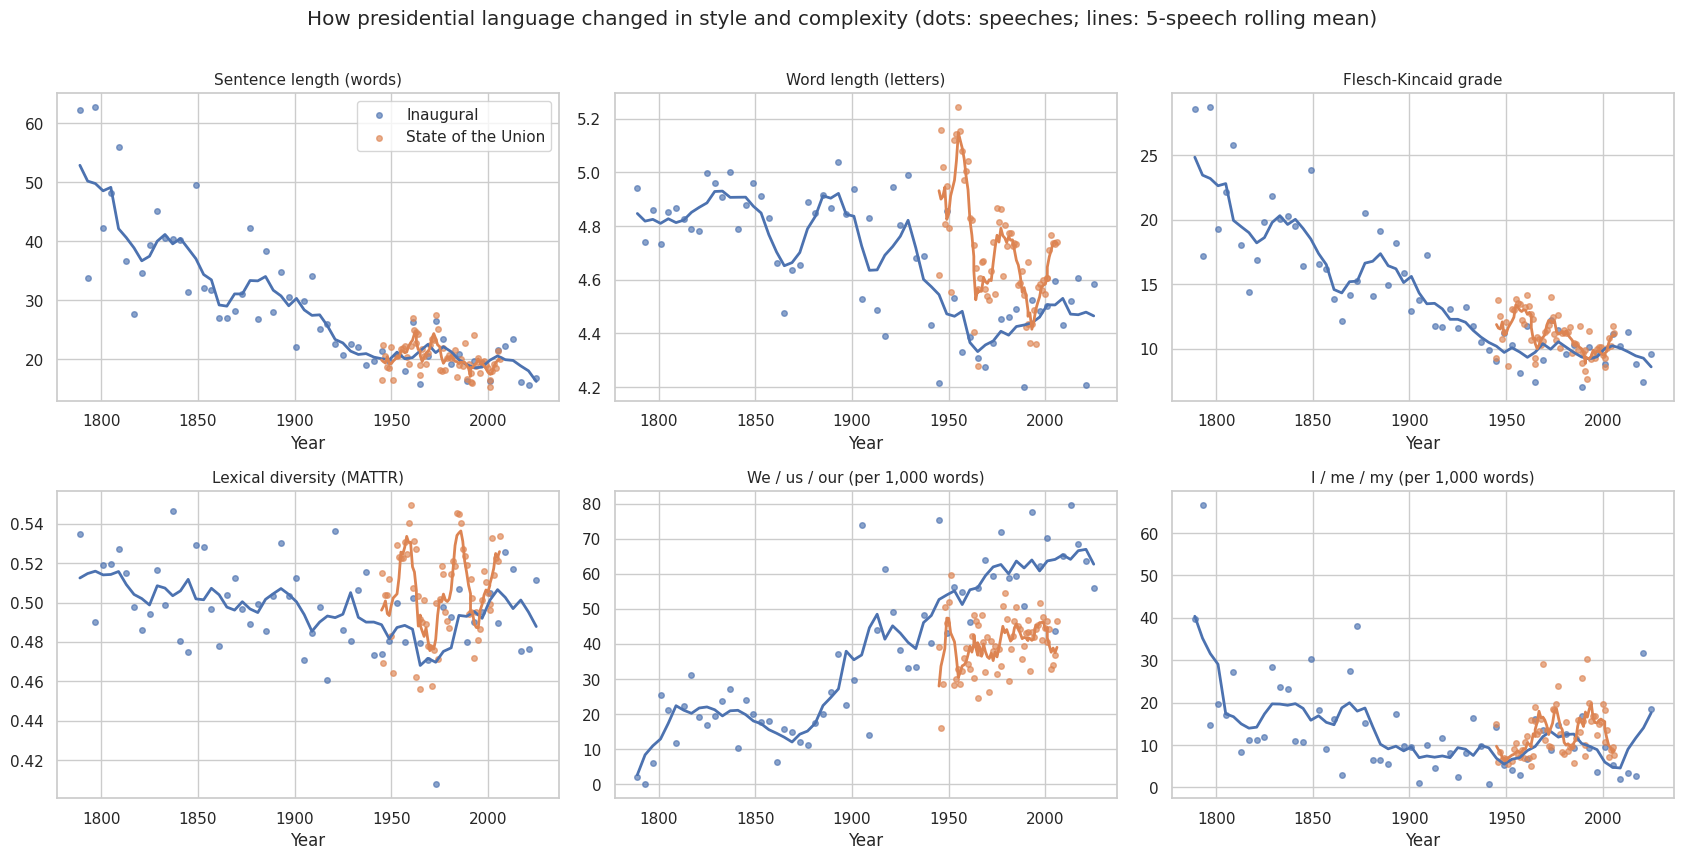

,Corpus,Measure,rho,p,Early mean,Late mean
0,Inaugural,Sentence length (words),-0.872,0.000,37.367,21.079
1,Inaugural,Word length (letters),-0.656,0.000,4.831,4.519
2,Inaugural,Flesch-Kincaid grade,-0.889,0.000,18.369,10.531
3,Inaugural,Lexical diversity (MATTR),-0.303,0.020,0.504,0.490
4,Inaugural,"We / us / our (per 1,000 words)",0.831,0.000,20.133,54.784
5,Inaugural,"I / me / my (per 1,000 words)",-0.437,0.000,17.943,9.465
6,State of the Union,Sentence length (words),-0.364,0.003,21.381,19.172
7,State of the Union,Word length (letters),-0.471,0.000,4.791,4.626
8,State of the Union,Flesch-Kincaid grade,-0.520,0.000,11.812,10.235
9,State of the Union,Lexical diversity (MATTR),0.052,0.678,0.501,0.510


In [16]:
def count_syllables(word):
    n = len(re.findall(r"[aeiouy]+", word))
    if word.endswith("e") and not word.endswith(("le", "ee")) and n > 1:
        n -= 1
    return max(n, 1)

def mattr(tokens, window=500, step=25):
    if len(tokens) < window:
        return np.nan
    return float(np.mean([len(set(tokens[i:i + window])) / window for i in range(0, len(tokens) - window + 1, step)]))

PRON = {"we": {"we", "us", "our", "ours", "ourselves"}, "i": {"i", "me", "my", "mine", "myself"}, "you": {"you", "your", "yours", "yourself"}}

def style_metrics(df):
    rows = []
    for _, r in df.iterrows():
        sents = [s for s in nltk.sent_tokenize(r["text"]) if len(s.split()) >= 2]
        toks = raw_tokens(r["text"])
        n_w = len(toks)
        syll = sum(count_syllables(w) for w in toks)
        rows.append({"corpus": r["corpus"], "year": r["year"], "president": r["president"], "words": n_w,
                     "Sentence length (words)": n_w / max(len(sents), 1),
                     "Word length (letters)": sum(map(len, toks)) / max(n_w, 1),
                     "Flesch-Kincaid grade": 0.39 * (n_w / max(len(sents), 1)) + 11.8 * (syll / max(n_w, 1)) - 15.59,
                     "Lexical diversity (MATTR)": mattr(toks),
                     "We / us / our (per 1,000 words)": sum(t in PRON["we"] for t in toks) / n_w * 1000,
                     "I / me / my (per 1,000 words)": sum(t in PRON["i"] for t in toks) / n_w * 1000})
    return pd.DataFrame(rows)

style = pd.concat([style_metrics(inaug), style_metrics(sotu)], ignore_index=True)
METRICS = [c for c in style.columns if c not in ("corpus", "year", "president", "words")]
style.to_csv("outputs/table_style_metrics_per_speech.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
colors = {"Inaugural": "#4c72b0", "State of the Union": "#dd8452"}
for ax, m in zip(axes.ravel(), METRICS):
    for name, g in style.groupby("corpus"):
        g = g.sort_values("year")
        ax.scatter(g.year, g[m], s=16, alpha=0.65, color=colors[name], label=name)
        ax.plot(g.year, g[m].rolling(5, center=True, min_periods=2).mean(), color=colors[name], lw=2)
    ax.set_title(m, fontsize=11); ax.set_xlabel("Year")
axes[0, 0].legend()
plt.suptitle("How presidential language changed in style and complexity (dots: speeches; lines: 5-speech rolling mean)", y=1.01)
save("12_style_trends")

rows = []
for name, g in style.groupby("corpus"):
    for m in METRICS:
        gg = g.dropna(subset=[m])
        r, p = stats.spearmanr(gg.year, gg[m])
        rows.append({"Corpus": name, "Measure": m, "rho": r, "p": p, "Early mean": gg[gg.year <= gg.year.median()][m].mean(),
                     "Late mean": gg[gg.year > gg.year.median()][m].mean()})
style_trends = pd.DataFrame(rows)
display(style_trends.round(3))
style_trends.to_csv("outputs/table_style_trends.csv", index=False)

## Phase 7: How the meaning context of a word changes


In [17]:
passages = passages.merge(sotu[["fileid", "era"]], on="fileid", how="left")
era_order = {e: i for i, e in enumerate(sorted(passages["era"].unique(), key=lambda e: sotu.loc[sotu.era == e, "year"].min()))}
passages["era_rank"] = passages["era"].map(era_order)
era_names = {i: f"E{i + 1} ({sotu.loc[sotu.era.map(era_order) == i, 'year'].min()}-{sotu.loc[sotu.era.map(era_order) == i, 'year'].max()})" for i in range(N_ERAS)}

sets = [set(s.split()) for s in passages["proc"]]
TARGETS = ["security", "freedom", "government", "economy"]

def collocates(target, mask, n=8, min_co=5):
    docs = [s for s, m in zip(sets, mask) if m]
    with_t = [s for s in docs if target in s]
    if len(with_t) < 10:
        return ["(too few passages)"]
    df_all = collections.Counter(w for s in docs for w in s)
    co = collections.Counter(w for s in with_t for w in s if w != target)
    N, Nt = len(docs), len(with_t)
    scored = [((c - Nt * df_all[w] / N) / np.sqrt(c), w) for w, c in co.items() if c >= min_co]       # t-score
    return [w for _, w in sorted(scored, reverse=True)[:n]]

coll_rows = []
for t in TARGETS:
    for e in range(N_ERAS):
        coll_rows.append({"Target": t, "Era": era_names[e], "Top collocates": ", ".join(collocates(t, (passages["era_rank"] == e).values))})
coll = pd.DataFrame(coll_rows)
pd.set_option("display.max_colwidth", 100)
display(coll)
coll.to_csv("outputs/table_collocates_by_era.csv", index=False)

,Target,Era,Top collocates
0,security,E1 (1945-1969),"social, military, health, defense, strength, system, age, insurance"
1,security,E2 (1970-1974),(too few passages)
2,security,E3 (1975-1992),"social, national, soviet, defense, middle, peace, east, military"
3,security,E4 (1993-2000),"social, surplus, medicare, debt, sound, peace, including, europe"
4,security,E5 (2001-2006),"social, retirement, homeland, benefit, worker, priority, younger, reform"
5,freedom,E1 (1945-1969),"world, free, peace, ideal, communism, asia, people, america"
6,freedom,E2 (1970-1974),"peace, nation, world, america, american"
7,freedom,E3 (1975-1992),"peace, america, world, democracy, great, free, hope, democratic"
8,freedom,E4 (1993-2000),"peace, world, democracy, prosperity, economy, union, trade, nation"
9,freedom,E5 (2001-2006),"friend, democracy, ally, terror, cause, democratic, peace, liberty"


## Phase 8: Key numbers in one place


In [18]:
print("=== CORPUS ===")
print(f"State of the Union: {len(sotu)} speeches, {sotu.year.min()}-{sotu.year.max()}, {sotu.n_words.sum():,} words, {len(passages):,} passages")
print(f"Inaugural: {len(inaug)} speeches, {inaug.year.min()}-{inaug.year.max()}, {inaug.n_words.sum():,} words")
print(f"Content tokens: {sum(all_counts.values()):,} | distinct lemmas: {len(all_counts):,} | topic-model vocabulary: {len(t_vocab):,}")
print("\n=== TRENDS ===")
print(f"{len(trend)} words tested; {len(sig)} significant ({(sig.rho > 0).sum()} rising, {(sig.rho < 0).sum()} falling)")
print("Top rising :", ", ".join(rising.word.head(8)))
print("Top falling:", ", ".join(falling.word.head(8)))
print(change_points[["word", "change_year", "mean_before", "mean_after", "p"]].round(3).to_string(index=False))
print("\n=== TOPICS ===")
print(f"Selected: {FINAL_ALGO}, k = {FINAL_K}, NPMI coherence = {coh[(coh.Algorithm == FINAL_ALGO) & (coh.k == FINAL_K)]['Coherence (NPMI)'].iloc[0]:.4f}")
print(topic_trends.head(3)[["Topic", "rho"]].round(3).to_string(index=False))
print(topic_trends.tail(3)[["Topic", "rho"]].round(3).to_string(index=False))
print("\n=== CLUSTERS AND ERAS ===")
print(f"K-means: k = {BEST_KC}, silhouette = {sil.silhouette.max():.3f}, ARI vs topics = {adjusted_rand_score(passages['topic'], passages['cluster']):.3f}")
print(eras[["Era", "start", "end", "speeches"]].to_string(index=False))
print("\n=== STYLE (Spearman rho with year) ===")
print(style_trends[["Corpus", "Measure", "rho", "Early mean", "Late mean"]].round(3).to_string(index=False))

=== CORPUS ===
State of the Union: 65 speeches, 1945-2006, 347,813 words, 2,866 passages
Inaugural: 60 speeches, 1789-2025, 141,073 words
Content tokens: 163,216 | distinct lemmas: 10,435 | topic-model vocabulary: 2,784

=== TRENDS ===
192 words tested; 90 significant (41 rising, 49 falling)
Top rising : child, reform, america, tonight, american, day, work, woman
Top falling: present, labor, expenditure, full, development, farm, increased, resource
     word  change_year  mean_before  mean_after     p
   soviet         1992       19.800       1.300 0.353
terrorist         2001        0.857      59.791 0.001
inflation         1985       19.166       4.222 0.057
communist         1970       11.594       1.526 0.001

=== TOPICS ===
Selected: NMF, k = 10, NPMI coherence = 0.2323
                      Topic   rho
  T3: child, school, parent 0.757
T10: america, american, god 0.579
       T4: tax, cut, budget 0.499
                           Topic    rho
        T1: world, peace, nation -0.54

## Export and versions

In [19]:
import importlib.metadata as md
print("Python:", sys.version.split()[0])
for lib in ["numpy", "pandas", "scipy", "scikit-learn", "nltk", "matplotlib", "seaborn"]:
    print(lib, md.version(lib))                    # put these in your report appendix

Python: 3.13.16
numpy 2.1.3
pandas 2.2.3
scipy 1.16.3
scikit-learn 1.6.1
nltk 3.9.1
matplotlib 3.10.0
seaborn 0.13.2


In [20]:
import shutil
shutil.make_archive("week4_outputs", "zip", "outputs")
try:
    from google.colab import files
    files.download("week4_outputs.zip")
except ImportError:
    print("Not running in Colab: find week4_outputs.zip in the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>